In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from sklearn.utils.class_weight import compute_class_weight

In [10]:
df = pd.read_csv("heart.csv")

print("Dataset Loaded Successfully")
print(df.head())
print("Dataset Shape:", df.shape)
print(df.info())

Dataset Loaded Successfully
   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR  \
0   40   M           ATA        140          289          0     Normal    172   
1   49   F           NAP        160          180          0     Normal    156   
2   37   M           ATA        130          283          0         ST     98   
3   48   F           ASY        138          214          0     Normal    108   
4   54   M           NAP        150          195          0     Normal    122   

  ExerciseAngina  Oldpeak ST_Slope  HeartDisease  
0              N      0.0       Up             0  
1              N      1.0     Flat             1  
2              N      0.0       Up             0  
3              Y      1.5     Flat             1  
4              N      0.0       Up             0  
Dataset Shape: (918, 12)
<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------    

In [11]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nTarget Distribution:")
print(df["HeartDisease"].value_counts())

Missing Values:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

Duplicate Rows: 0

Target Distribution:
HeartDisease
1    508
0    410
Name: count, dtype: int64


In [12]:
X = df.drop("HeartDisease", axis=1)
y = df["HeartDisease"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (918, 11)
Target Shape: (918,)


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (734, 11)
Testing Data: (184, 11)


In [14]:
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class Weights:", class_weights)

Class Weights: {np.int64(0): np.float64(1.1189024390243902), np.int64(1): np.float64(0.9039408866995073)}


In [15]:
num_cols = X_train.select_dtypes(include=np.number).columns

cat_cols = X_train.select_dtypes(exclude=np.number).columns

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Preprocessing Completed")
print("Training Shape:", X_train_processed.shape)
print("Testing Shape:", X_test_processed.shape)

Preprocessing Completed
Training Shape: (734, 20)
Testing Shape: (184, 20)


# Create Multiple Classifiers

In [16]:
models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        class_weight="balanced",
        n_estimators=100,
        random_state=42
    ),

    "SVM": SVC(
        class_weight="balanced",
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    )
}

# Train and Evaluate Models

In [19]:
results = []
trained_models = {}

for name, model in models.items():

    model.fit(X_train_processed, y_train)

    y_pred = model.predict(X_test_processed)

    trained_models[name] = model

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0)
    })

results_df = pd.DataFrame(results)

print(results_df)

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.896739   0.887850  0.931373  0.909091
1        Decision Tree  0.782609   0.803922  0.803922  0.803922
2        Random Forest  0.902174   0.896226  0.931373  0.913462
3                  SVM  0.891304   0.894231  0.911765  0.902913
4                  KNN  0.896739   0.910891  0.901961  0.906404


In [20]:
results_df["Custom Score"] = (
    0.30 * results_df["Precision"] +
    0.40 * results_df["Recall"] +
    0.30 * results_df["F1 Score"]
)

results_df = results_df.sort_values(
    by="Custom Score",
    ascending=False
).reset_index(drop=True)

print(results_df)

                 Model  Accuracy  Precision    Recall  F1 Score  Custom Score
0        Random Forest  0.902174   0.896226  0.931373  0.913462      0.915455
1  Logistic Regression  0.896739   0.887850  0.931373  0.909091      0.911631
2                  KNN  0.896739   0.910891  0.901961  0.906404      0.905973
3                  SVM  0.891304   0.894231  0.911765  0.902913      0.903849
4        Decision Tree  0.782609   0.803922  0.803922  0.803922      0.803922


# Select Best Model

In [21]:
best_model_name = results_df.loc[0, "Model"]

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

print("Best Custom Score:",
      results_df.loc[0, "Custom Score"])

Best Model: Random Forest
Best Custom Score: 0.9154554056746065


# Detailed Classification Report

In [22]:
y_pred = best_model.predict(X_test_processed)

print("Best Model:", best_model_name)

print("\nClassification Report:")

print(classification_report(y_test, y_pred))

Best Model: Random Forest

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.87      0.89        82
           1       0.90      0.93      0.91       102

    accuracy                           0.90       184
   macro avg       0.90      0.90      0.90       184
weighted avg       0.90      0.90      0.90       184



# Confusion Matrix

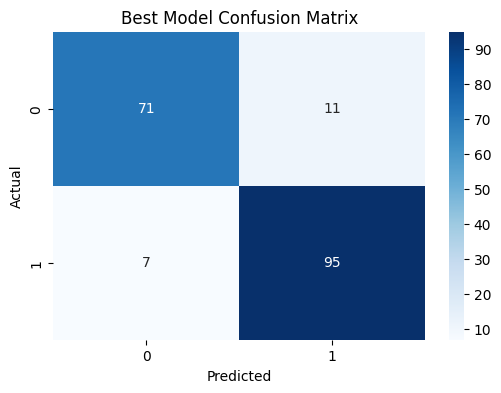

In [23]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Best Model Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

# Performance Comparison Graph

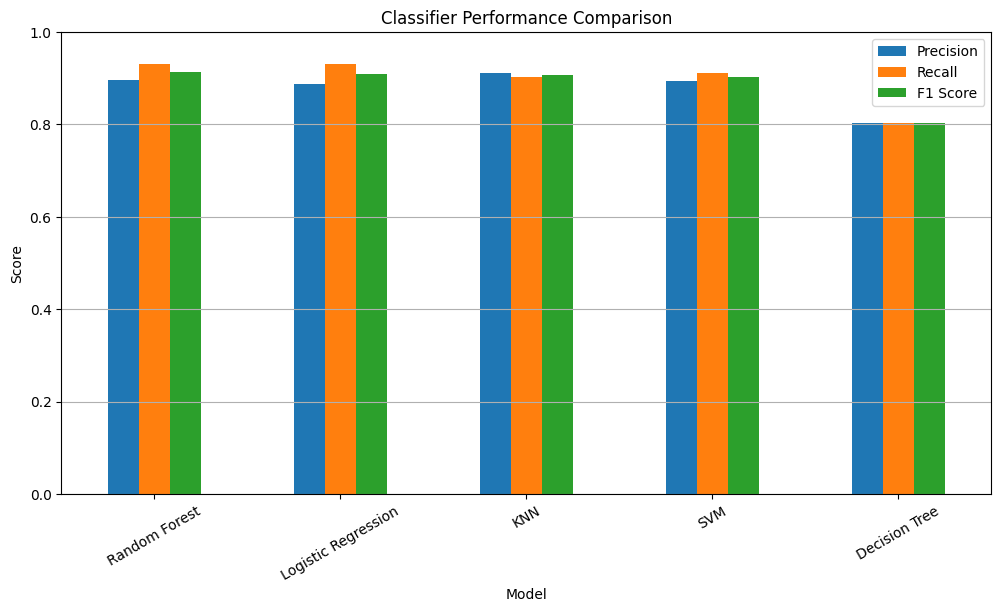

In [24]:
results_df.set_index("Model")[
    ["Precision", "Recall", "F1 Score"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Classifier Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=30)
plt.grid(axis="y")

plt.show()

# Final Performance Analysis

In [27]:
print("========== FINAL MODEL ANALYSIS ==========")

print("Selected Model:", best_model_name)

print("\nPerformance Metrics:")

print(results_df.iloc[0])

print("\nReason for Selection:")

print("""
The best model is selected using a custom weighted score.

Precision Weight = 30%
Recall Weight = 40%
F1 Score Weight = 30%

Recall receives higher importance because
missing a heart disease case can be risky.

The model with the highest custom score
is selected as the best model.
""")

========== FINAL MODEL ANALYSIS ==========
Selected Model: Random Forest

Performance Metrics:
Model           Random Forest
Accuracy             0.902174
Precision            0.896226
Recall               0.931373
F1 Score             0.913462
Custom Score         0.915455
Name: 0, dtype: object

Reason for Selection:

The best model is selected using a custom weighted score.

Precision Weight = 30%
Recall Weight = 40%
F1 Score Weight = 30%

Recall receives higher importance because
missing a heart disease case can be risky.

The model with the highest custom score
is selected as the best model.



# Conclusion

# Multiple machine learning classifiers were implemented and evaluated for Heart Disease Prediction. The models were compared using Accuracy, Precision, Recall, and F1-score.

# Class imbalance was handled using balanced class weights for supported classifiers. A custom weighted scoring strategy was applied, assigning 30% weight to Precision, 40% to Recall, and 30% to F1-score.

# The model achieving the highest custom score was selected as the best model. Recall was given higher priority to reduce the risk of missing potential heart disease cases.